In [41]:
from ACO_adaptado import *

## Definimos los parámtros fijos y los rangos de los hiperparámtros que buscamos optimizar

In [42]:
N = 30
T = 200
alpha = (np.linspace(1, 1.5, 5))
beta = (np.linspace(0.5, 5, 5))
rho = (np.linspace(0.2, 0.99, 5))
Q = (np.linspace(25, 100, 4))
cerrado = True
random_state = (123, 1234, 12345)
inicio = 13

file_path = "matriz_distancias.csv"
dist_matrix = LoadDistanceMatrix(file_path)

print(alpha)
print(beta)
print(rho)
print(Q)

[1.    1.125 1.25  1.375 1.5  ]
[0.5   1.625 2.75  3.875 5.   ]
[0.2    0.3975 0.595  0.7925 0.99  ]
[ 25.  50.  75. 100.]


## Realizamos la búsqueda en rejilla (grid search)

In [43]:
def ejecuta_config(N, T, alpha, beta, rho, Q, cerrado, random_state, inicio, dist_matrix):
    best_outputs, best_outputs_global, best_ant_f, best_ant_x = AntsColonyOptimization(N, T, alpha, beta, rho, Q, dist_matrix, cerrado, random_state, inicio)
    return {'options': (alpha, beta, rho, Q),
            'semilla': random_state,
            'outputs': best_outputs,
            'outputs_global': best_outputs_global,
            'fitness': best_ant_f,
            'solution': best_ant_x.copy()}

In [44]:
import itertools
import pandas as pd
from joblib import Parallel, delayed

combinaciones = list(itertools.product(alpha, beta, rho, Q, random_state))

resultados = Parallel(n_jobs=-1, verbose=10)(
    delayed(ejecuta_config)(N, T, a, b, r, q, cerrado, s, inicio, dist_matrix)
    for a, b, r, q, s in combinaciones)

filas = []
for res in resultados:
    a, b, r, q = res['options']
    filas.append({"alpha": a,
                  "beta": b,
                  "rho": r,
                  "Q": q,
                  "semilla": res['semilla'],
                  "fitness": res['fitness'],
                  "solution": res['solution']})

[Parallel(n_jobs=-1)]: Using backend LokyBackend with 16 concurrent workers.
[Parallel(n_jobs=-1)]: Done   9 tasks      | elapsed:   22.2s
[Parallel(n_jobs=-1)]: Done  18 tasks      | elapsed:   40.2s
[Parallel(n_jobs=-1)]: Done  29 tasks      | elapsed:   42.1s
[Parallel(n_jobs=-1)]: Done  40 tasks      | elapsed:  1.0min
[Parallel(n_jobs=-1)]: Done  53 tasks      | elapsed:  1.3min
[Parallel(n_jobs=-1)]: Done  66 tasks      | elapsed:  1.6min
[Parallel(n_jobs=-1)]: Done  81 tasks      | elapsed:  1.9min
[Parallel(n_jobs=-1)]: Done  96 tasks      | elapsed:  2.0min
[Parallel(n_jobs=-1)]: Done 113 tasks      | elapsed:  2.5min
[Parallel(n_jobs=-1)]: Done 130 tasks      | elapsed:  2.8min
[Parallel(n_jobs=-1)]: Done 149 tasks      | elapsed:  3.2min
[Parallel(n_jobs=-1)]: Done 168 tasks      | elapsed:  3.5min
[Parallel(n_jobs=-1)]: Done 189 tasks      | elapsed:  3.9min
[Parallel(n_jobs=-1)]: Done 210 tasks      | elapsed:  4.4min
[Parallel(n_jobs=-1)]: Done 233 tasks      | elapsed:  

## Analisis de resultados

In [47]:
df = pd.DataFrame(filas)

df["solution"] = df["solution"].apply(list)
df.to_pickle("resultados_grid.pkl")      # conserva todo tal cual
df.drop(columns="solution").to_csv("resultados_grid.csv", index=False)

df.to_csv("resultados_grid.csv", index=False)   # copia de seguridad

resumen = (df.groupby(["alpha", "beta", "rho", "Q"])["fitness"]
             .agg(["mean", "std", "min"])
             .sort_values("mean")
             .reset_index())

resumen.head(10)

,alpha,beta,rho,Q,mean,std,min
0,1.000,3.875,0.3975,100.0,18161.895212,433.487995,17904.003124
1,1.125,1.625,0.2000,50.0,18207.353323,59.659382,18151.814212
2,1.375,1.625,0.2000,75.0,18224.599169,426.749381,17935.044926
3,1.000,3.875,0.3975,75.0,18260.760123,256.399663,18002.872880
4,1.250,1.625,0.2000,50.0,18263.147253,497.009955,17738.321840
5,1.125,3.875,0.2000,25.0,18327.910479,278.676961,18086.901501
6,1.000,2.750,0.5950,25.0,18353.902579,481.896847,17808.724914
7,1.000,3.875,0.5950,100.0,18360.737081,321.690050,18075.503595
8,1.000,2.750,0.2000,25.0,18362.882077,232.237924,18211.895113
9,1.125,1.625,0.5950,50.0,18363.782069,399.553328,17935.634996


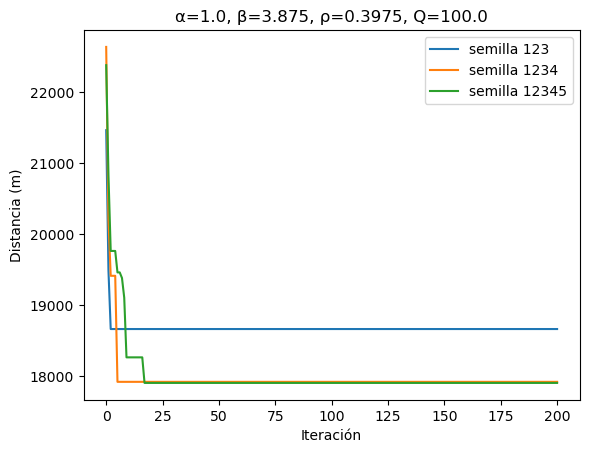

In [48]:
mejor = resumen.iloc[0]
for res in resultados:
    if res['options'] == (mejor.alpha, mejor.beta, mejor.rho, mejor.Q):
        plt.plot(res['outputs_global'], label=f"semilla {res['semilla']}")
plt.xlabel("Iteración"); plt.ylabel("Distancia (m)")
plt.title(f"α={mejor.alpha}, β={mejor.beta}, ρ={mejor.rho}, Q={mejor.Q}")
plt.legend(); plt.show()